# Economics S5040 — Problem Set 7 Answer Key
## Optimal Saving

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Problem 1. Cake Eating

The Bellman equation is
$$
V(x)=\max_{0\le c\le x}\{u(c)+\beta V(x-c)\}.
$$

The first-order condition and envelope condition imply
$$
u'(c_t)=\beta u'(c_{t+1}).
$$

For CRRA utility,
$$
u'(c)=c^{-\rho},
$$
so
$$
\frac{c_{t+1}}{c_t}=\beta^{1/\rho}.
$$

Let $q=\beta^{1/\rho}$. Since $c_{t+j}=q^j c_t$ and the entire cake is
eventually consumed,
$$
x_t=\sum_{j=0}^\infty q^j c_t=\frac{c_t}{1-q}.
$$

Hence
$$
\boxed{c^*(x)=(1-\beta^{1/\rho})x}
$$
and
$$
\boxed{a^*(x)=\beta^{1/\rho}x}.
$$

Iterations: 555
Bellman error: 9.581850690665306e-08
Max policy error: 0.003175574539179271


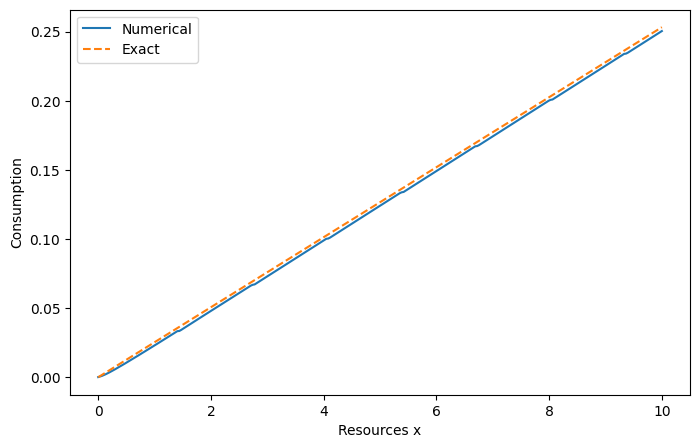

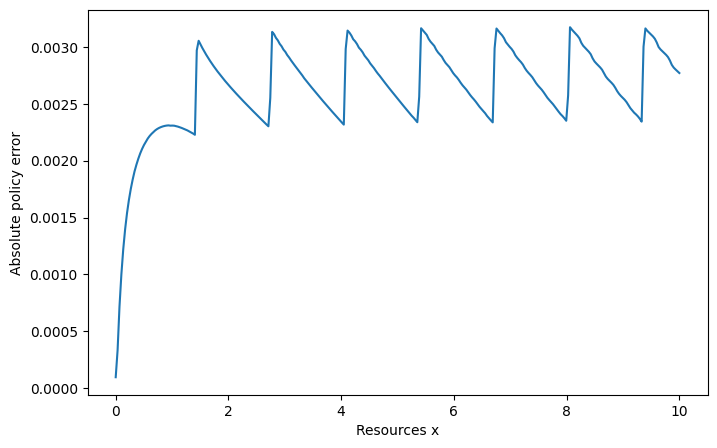

In [2]:
def u(c, rho):
    if c <= 0:
        return -1e14
    if abs(rho - 1.0) < 1e-12:
        return np.log(c)
    return (c**(1-rho)-1)/(1-rho)

def solve_cake(beta=0.95, rho=2.0, N=300, tol=1e-7, max_iter=5000):
    x_grid = np.linspace(1e-4, 10.0, N)
    v = np.array([u(x, rho) for x in x_grid])

    policy = np.empty(N)

    for it in range(max_iter):
        new_v = np.empty_like(v)
        new_policy = np.empty_like(v)

        for i, x in enumerate(x_grid):
            def objective(c):
                xp = x - c
                cont = np.interp(xp, x_grid, v)
                return -(u(c, rho) + beta * cont)

            res = minimize_scalar(
                objective,
                bounds=(1e-10, x),
                method="bounded"
            )
            new_v[i] = -res.fun
            new_policy[i] = res.x

        err = np.max(np.abs(new_v-v))
        v = new_v
        policy = new_policy

        if err < tol:
            break

    exact = (1-beta**(1/rho))*x_grid
    return x_grid, v, policy, exact, it+1, err

x_grid, v, policy, exact, iters, err = solve_cake()

print("Iterations:", iters)
print("Bellman error:", err)
print("Max policy error:", np.max(np.abs(policy-exact)))

plt.figure(figsize=(8,5))
plt.plot(x_grid, policy, label="Numerical")
plt.plot(x_grid, exact, "--", label="Exact")
plt.xlabel("Resources x")
plt.ylabel("Consumption")
plt.legend()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(x_grid, np.abs(policy-exact))
plt.xlabel("Resources x")
plt.ylabel("Absolute policy error")
plt.show()

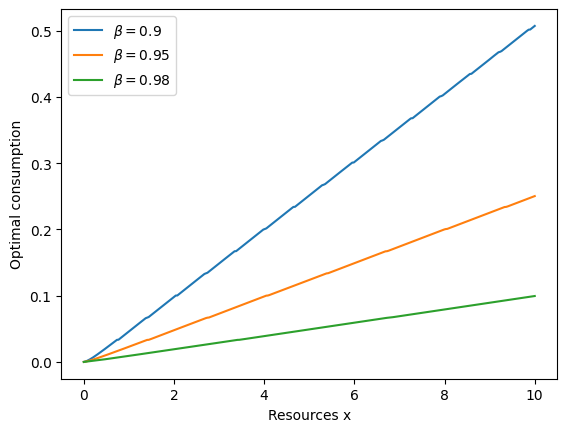

In [4]:
for b in [0.90, 0.95, 0.98]:
    xg, _, pol, ex, _, _ = solve_cake(beta=b)
    plt.plot(xg, pol, label=fr"$\beta={b}$")
plt.xlabel("Resources x")
plt.ylabel("Optimal consumption")
plt.legend()
plt.show()

Higher $\beta$ means greater patience. The household consumes a smaller
fraction of current resources and saves more.

# Problem 2. Stochastic Neoclassical Growth

The Euler equation is
$$
\frac{1}{c_t}
=
\beta\frac{1}{c_{t+1}}
\left[
\alpha A k_{t+1}^{\alpha-1}+1-\delta
\right].
$$

At the deterministic steady state,
$$
1=
\beta\left[\alpha A(k^*)^{\alpha-1}+1-\delta\right].
$$

Thus
$$
A=
\frac{1/\beta-(1-\delta)}
{\alpha(k^*)^{\alpha-1}}.
$$

In [5]:
alpha = 0.33
beta = 0.96
delta = 0.10
kss = 400.0

A = (1/beta - (1-delta)) / (alpha * kss**(alpha-1))
yss = A * kss**alpha

print("A =", A)
print("y* =", yss)

A = 23.775733801180635
y* = 171.71717171717174


Iterations: 378
Tolerance: 1e-06


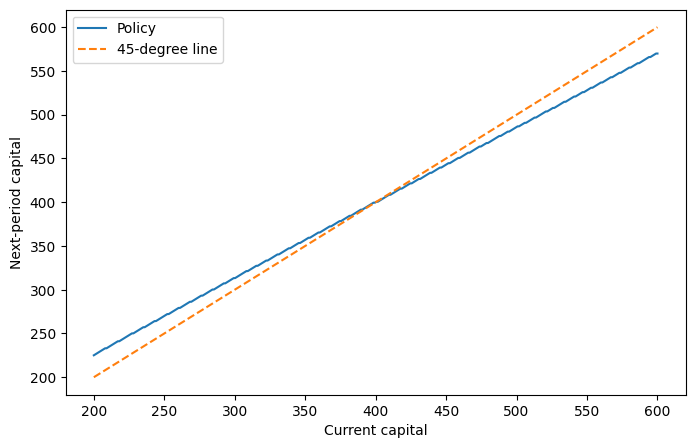

In [6]:
# Deterministic VFI

k_grid = np.linspace(0.5*kss, 1.5*kss, 400)
N = len(k_grid)

V = np.zeros(N)
pol_idx = np.zeros(N, dtype=int)

tol = 1e-6

for it in range(5000):
    V_new = np.empty_like(V)

    for i, k in enumerate(k_grid):
        resources = A*k**alpha + (1-delta)*k
        c = resources - k_grid
        feasible = c > 0

        vals = np.full(N, -np.inf)
        vals[feasible] = np.log(c[feasible]) + beta*V[feasible]

        j = np.argmax(vals)
        V_new[i] = vals[j]
        pol_idx[i] = j

    err = np.max(np.abs(V_new-V))
    V = V_new

    if err < tol:
        break

k_policy = k_grid[pol_idx]

print("Iterations:", it+1)
print("Tolerance:", tol)

plt.figure(figsize=(8,5))
plt.plot(k_grid, k_policy, label="Policy")
plt.plot(k_grid, k_grid, "--", label="45-degree line")
plt.xlabel("Current capital")
plt.ylabel("Next-period capital")
plt.legend()
plt.show()

The intersection with the 45-degree line satisfies $k'=k$, which is exactly
the definition of a steady state under the policy.

In [7]:
# Markov chain

P_RR = 1 - 1/4
P_BB = 1 - 1/6

P = np.array([
    [P_RR, 1-P_RR-0.01, 0.01],
    [0.03, 1-0.03-0.04, 0.04],
    [0.02, 1-0.02-P_BB, P_BB]
])

print(P)
print(P.sum(axis=1))

# stationary distribution
Astat = P.T - np.eye(3)
Astat[-1,:] = 1
bstat = np.array([0.0,0.0,1.0])
pi = np.linalg.solve(Astat, bstat)

print("pi =", pi)

[[0.75       0.24       0.01      ]
 [0.03       0.93       0.04      ]
 [0.02       0.14666667 0.83333333]]
[1. 1. 1.]
pi = [0.10075275 0.72032426 0.17892299]


The stationary distribution gives the long-run fraction of quarters spent in
recession, normal, and boom states.

/var/folders/m5/j7tmdq0x5wsggd4ym45qhhr80000gn/T/ipykernel_54707/2515055393.py:11: RuntimeWarning: divide by zero encountered in matmul
  EV = P[iz] @ V
/var/folders/m5/j7tmdq0x5wsggd4ym45qhhr80000gn/T/ipykernel_54707/2515055393.py:11: RuntimeWarning: overflow encountered in matmul
  EV = P[iz] @ V
/var/folders/m5/j7tmdq0x5wsggd4ym45qhhr80000gn/T/ipykernel_54707/2515055393.py:11: RuntimeWarning: invalid value encountered in matmul
  EV = P[iz] @ V


Iterations: 378
Bellman error: 9.99066386953018e-07


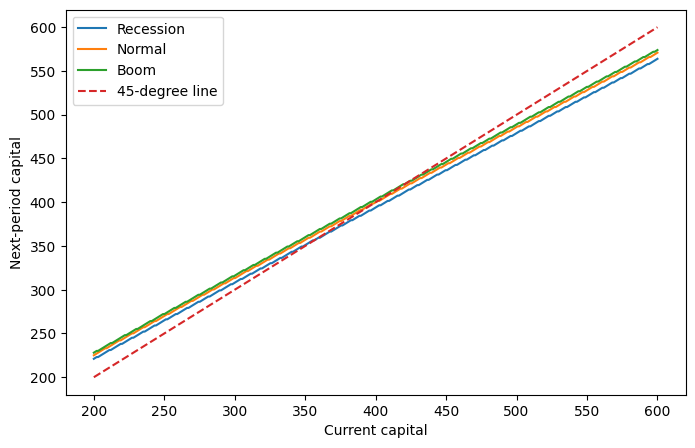

In [8]:
# Stochastic growth VFI

z_vals = np.array([0.95, 1.00, 1.026])
V = np.zeros((3, N))
pol_idx = np.zeros((3, N), dtype=int)

for it in range(5000):
    V_new = np.empty_like(V)

    for iz, z in enumerate(z_vals):
        EV = P[iz] @ V

        for i, k in enumerate(k_grid):
            resources = A*z*k**alpha + (1-delta)*k
            c = resources - k_grid
            feasible = c > 0

            vals = np.full(N, -np.inf)
            vals[feasible] = np.log(c[feasible]) + beta*EV[feasible]

            j = np.argmax(vals)
            V_new[iz,i] = vals[j]
            pol_idx[iz,i] = j

    err = np.max(np.abs(V_new-V))
    V = V_new

    if err < 1e-6:
        break

k_pol = k_grid[pol_idx]

print("Iterations:", it+1)
print("Bellman error:", err)

plt.figure(figsize=(8,5))
for iz, label in enumerate(["Recession","Normal","Boom"]):
    plt.plot(k_grid, k_pol[iz], label=label)
plt.plot(k_grid, k_grid, "--", label="45-degree line")
plt.xlabel("Current capital")
plt.ylabel("Next-period capital")
plt.legend()
plt.show()

Higher current productivity raises available resources and generally shifts the
saving policy upward. The household also responds to uncertainty by choosing a
policy that reflects future risk, although the exact magnitude of
precautionary saving depends on preferences, persistence, and the calibration.

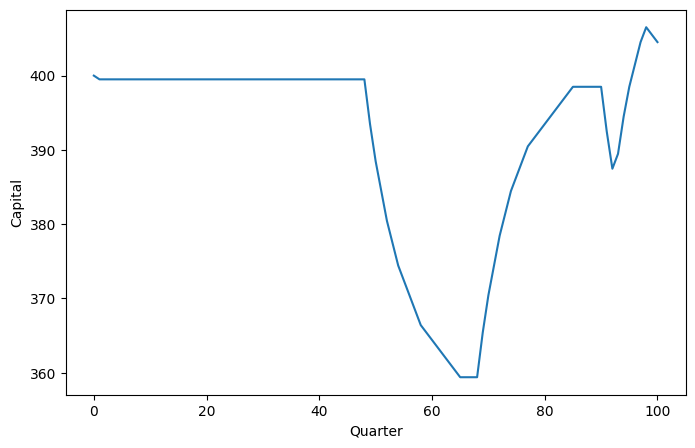

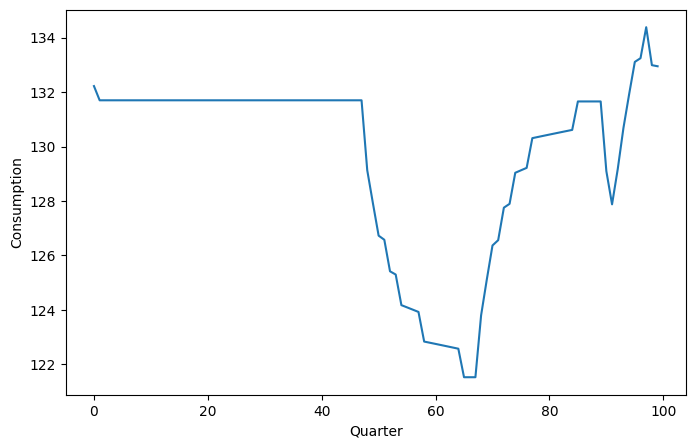

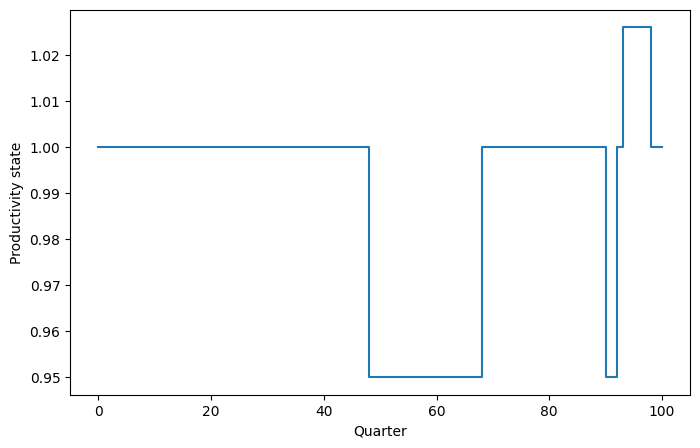

In [9]:
# Simulation

T = 100
rng = np.random.default_rng(12345)

k_sim = np.empty(T+1)
z_idx = np.empty(T+1, dtype=int)
y_sim = np.empty(T)
c_sim = np.empty(T)

k_sim[0] = kss
z_idx[0] = rng.choice(3, p=pi)

for t in range(T):
    i = np.argmin(np.abs(k_grid-k_sim[t]))
    iz = z_idx[t]

    k_next = k_pol[iz, i]
    z = z_vals[iz]

    y_sim[t] = A*z*k_sim[t]**alpha
    c_sim[t] = y_sim[t] + (1-delta)*k_sim[t] - k_next
    k_sim[t+1] = k_next
    z_idx[t+1] = rng.choice(3, p=P[iz])

plt.figure(figsize=(8,5))
plt.plot(k_sim)
plt.ylabel("Capital")
plt.xlabel("Quarter")
plt.show()

plt.figure(figsize=(8,5))
plt.plot(c_sim)
plt.ylabel("Consumption")
plt.xlabel("Quarter")
plt.show()

plt.figure(figsize=(8,5))
plt.step(np.arange(T+1), z_vals[z_idx], where="post")
plt.ylabel("Productivity state")
plt.xlabel("Quarter")
plt.show()

# Problem 3. Saving with Labor Income

Iterations: 363
Bellman error: 9.67110729277465e-08


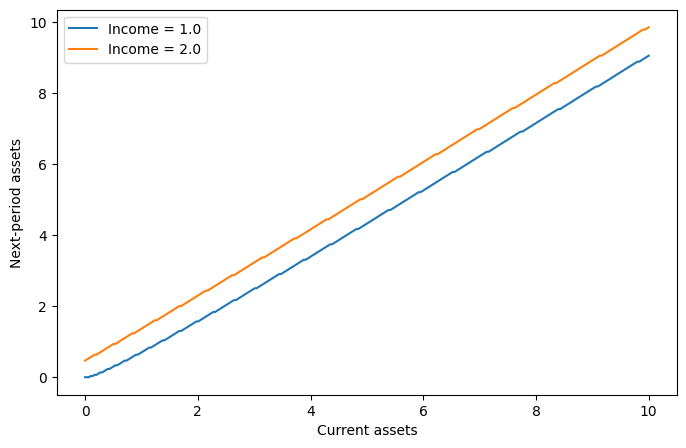

In [10]:
R = 1.02
beta = 0.96
y_vals = np.array([1.0, 2.0])
P_y = np.array([
    [0.90, 0.10],
    [0.20, 0.80]
])
a_grid = np.linspace(0.0, 10.0, 300)

Ny = len(y_vals)
Na = len(a_grid)

V = np.zeros((Ny,Na))
pol_idx = np.zeros((Ny,Na), dtype=int)

for it in range(5000):
    V_new = np.empty_like(V)

    for iy, y in enumerate(y_vals):
        EV = P_y[iy] @ V

        for ia, a in enumerate(a_grid):
            resources = R*a + y
            c = resources - a_grid
            feasible = c > 0

            vals = np.full(Na, -np.inf)
            vals[feasible] = np.log(c[feasible]) + beta*EV[feasible]

            j = np.argmax(vals)
            V_new[iy,ia] = vals[j]
            pol_idx[iy,ia] = j

    err = np.max(np.abs(V_new-V))
    V = V_new

    if err < 1e-7:
        break

a_policy = a_grid[pol_idx]

print("Iterations:", it+1)
print("Bellman error:", err)

plt.figure(figsize=(8,5))
for iy, y in enumerate(y_vals):
    plt.plot(a_grid, a_policy[iy], label=f"Income = {y}")
plt.xlabel("Current assets")
plt.ylabel("Next-period assets")
plt.legend()
plt.show()

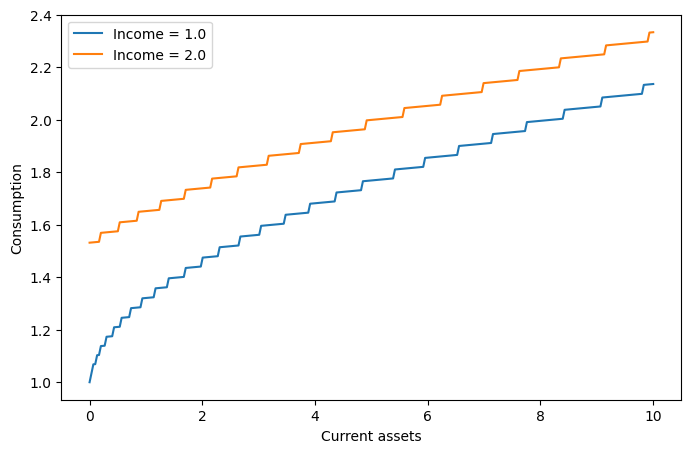

In [11]:
c_policy = np.empty_like(a_policy)

for iy, y in enumerate(y_vals):
    c_policy[iy] = R*a_grid + y - a_policy[iy]

plt.figure(figsize=(8,5))
for iy, y in enumerate(y_vals):
    plt.plot(a_grid, c_policy[iy], label=f"Income = {y}")
plt.xlabel("Current assets")
plt.ylabel("Consumption")
plt.legend()
plt.show()

At a given asset level, the high-income household generally chooses higher
next-period assets because current resources are higher. The borrowing
constraint $a'\ge0$ prevents the household from using negative assets to
bring future income into the present.

Relative to cake eating, saving now serves not only to move consumption across
time but also to buffer fluctuations in labor income. This is the beginning of
precautionary saving and self-insurance.

# What surprised me?

A good response should identify a specific numerical or policy result and
explain why it was unexpected.